In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('C:/Users/cesar/Desktop/PRactica/Dia_5/raw_dataset.csv')

# Parte 1 - Limpieza de dataframe

## Datos del dataframe

In [ ]:
df.describe()

In [ ]:
df.info()

## Asimetria

In [5]:
# Mostrar asimetria de las variables numericas:
print(df['Edad'].skew())
print(df['Monto_Compra'].skew())
print(df['Puntuacion_Gasto'].skew())

3.0559978383866504
10.016944710675544
1.5319940407547337


## Tratamiento de valores duplicados

In [6]:
# Evaluar duplicados:
duplicados = df[df.duplicated()]

In [7]:
# Dejo el original y borro los duplicados:
df.drop_duplicates(keep='first', inplace=True)

## Tratamiento de valores nulos

In [8]:
# Buscar nulos
df.isna().sum()

ID_Cliente             0
Edad                  89
Ingresos_Anuales      78
Monto_Compra          57
Puntuacion_Gasto       0
Categoria_Producto     0
Fecha_Registro         0
dtype: int64

In [9]:
# Filtra y muestra solo las filas con valores nulos de todo el dataframe:
print(df[df.isna().any(axis=1)])

     ID_Cliente  Edad Ingresos_Anuales  Monto_Compra  Puntuacion_Gasto  \
1      CLI-1001  36.0         63245.56           NaN              19.0   
2      CLI-1002   NaN       $37,638.33        944.35              14.0   
13     CLI-1013  15.0       $24,016.28           NaN              23.0   
19     CLI-1019  21.0              NaN       1061.18              11.0   
26     CLI-1026  24.0       $37,153.08           NaN              17.0   
...         ...   ...              ...           ...               ...   
1014   CLI-1483  40.0              NaN        824.93              20.0   
1023   CLI-1650   NaN       $51,419.87        772.93              13.0   
1027   CLI-1307   NaN       $36,117.35       1163.54              26.0   
1028   CLI-1869   NaN       $28,382.03       1051.53              19.0   
1033   CLI-1255   NaN         17574.70        886.52              19.0   

     Categoria_Producto Fecha_Registro  
1           Electrónica     2023-01-02  
2                  Ropa     2

In [10]:
# Elimino todas las filas que contengan un valor nulo:
df = df.dropna()

## Tratamiento de variables de texto

In [11]:
# Eliminar signos y puntuaciones y convertir la variable a flotante:
df['Ingresos_Anuales'] = df['Ingresos_Anuales'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).str.replace('USD', '', regex=False).astype(float)

In [12]:
# Pasar variables a minusculas:
df['Categoria_Producto'] = df['Categoria_Producto'].str.lower()

## Tratamiento de valores atipicos (outliers)

In [50]:
# Gestionar valores atipicos (outliers) para Edad:

Q1 = df['Edad'].quantile(0.25)
Q3 = df['Edad'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - (1.5 * IQR)
limite_superior = Q3 + (1.5 * IQR)

clean_df = df[(df['Edad'] >= limite_inferior) & (df['Edad'] <= limite_superior)]

In [51]:
# Gestionar valores atipicos (outliers) para Monto_Compra:

Q1 = df['Monto_Compra'].quantile(0.25)
Q3 = df['Monto_Compra'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - (1.5 * IQR)
limite_superior = Q3 + (1.5 * IQR)

clean_df = clean_df[(clean_df['Monto_Compra'] >= limite_inferior) & (clean_df['Monto_Compra'] <= limite_superior)]

# Parte 2 - Visualizacion

<Axes: title={'center': 'Scatter plot entre variable predictora y variable objetivo'}, xlabel='Ingresos_Anuales', ylabel='Monto_Compra'>

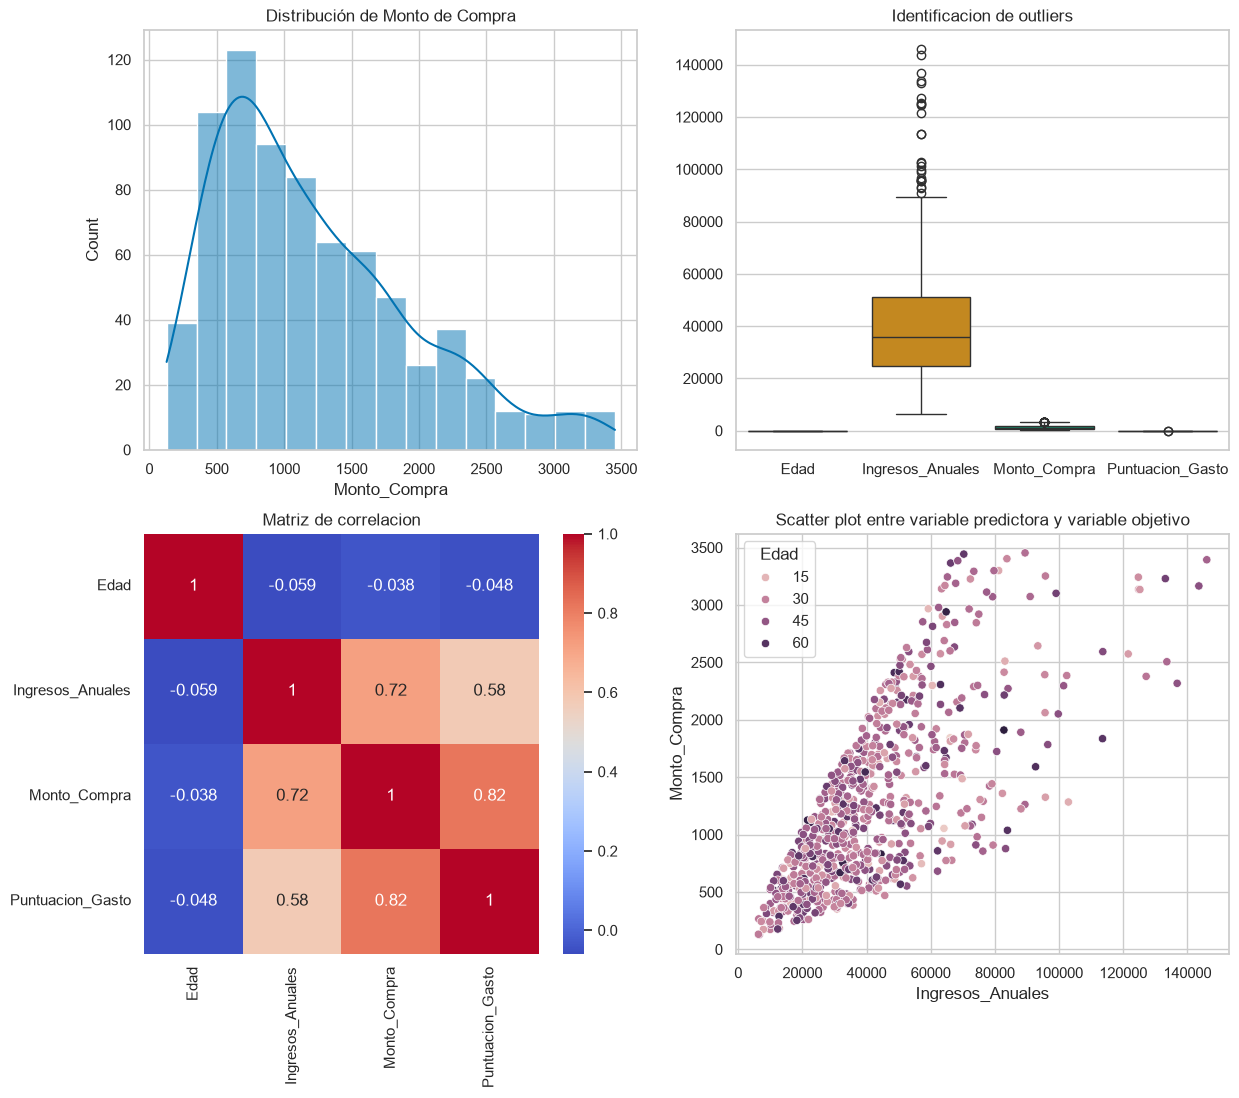

In [52]:
sns.set_theme(style="whitegrid", palette="colorblind")
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14,12))

axes[0, 0].set_title("Distribución de Monto de Compra")
sns.histplot(clean_df['Monto_Compra'], kde=True, ax=axes[0, 0])

axes[0,1].set_title("Identificacion de outliers")
sns.boxplot(clean_df, ax=axes[0, 1])

corr_df = clean_df.loc[:, ['Edad', 'Ingresos_Anuales', 'Monto_Compra', 'Puntuacion_Gasto']].copy()
correlation_matrix = corr_df.corr(method='pearson')
axes[1,0].set_title("Matriz de correlacion")
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", ax=axes[1,0])

axes[1,1].set_title("Scatter plot entre variable predictora y variable objetivo")
sns.scatterplot(clean_df, x=clean_df['Ingresos_Anuales'], y=clean_df['Monto_Compra'], hue=clean_df['Edad'], ax=axes[1,1])